In [5]:
import pandas as pd

df = pd.read_csv("/content/student/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:
   !unzip -o /content/archive.zip -d /content
   !ls /content

Archive:  /content/archive.zip
  inflating: /content/.student.zip_old  
  inflating: /content/student/student-mat.csv  
  inflating: /content/student/student-merge.R  
  inflating: /content/student/student-por.csv  
  inflating: /content/student/student.txt  
archive.zip  sample_data  student


In [7]:
print(df.shape)
print(df.isnull().sum().sum())
df[["age", "studytime", "failures", "absences", "G1", "G2", "G3"]].describe()

(395, 33)
0


,age,studytime,failures,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,0.334177,5.708861,10.908861,10.713924,10.415190
std,1.276043,0.839240,0.743651,8.003096,3.319195,3.761505,4.581443
min,15.000000,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,1.000000,0.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,2.000000,0.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,2.000000,0.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,3.000000,75.000000,19.000000,19.000000,20.000000


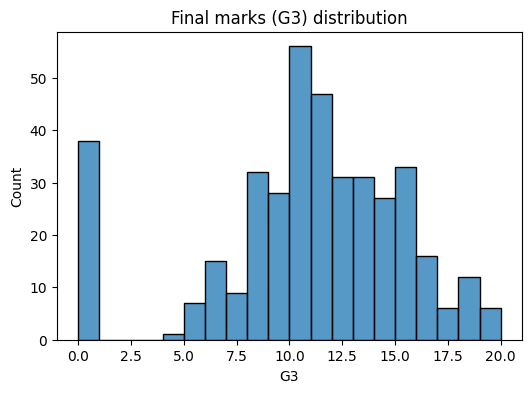

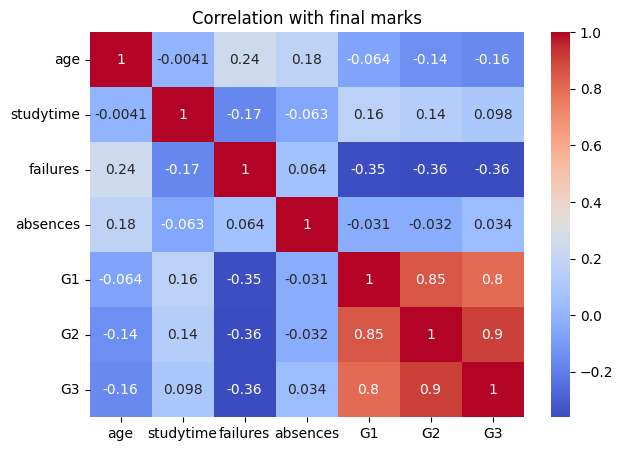

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.histplot(df["G3"], bins=20)
plt.title("Final marks (G3) distribution")
plt.show()

plt.figure(figsize=(7, 5))
cols = ["age", "studytime", "failures", "absences", "G1", "G2", "G3"]
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation with final marks")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

def run(features, name):
    X = df[features]
    y = df["G3"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name)
    print("Average error (marks):", round(mean_absolute_error(y_test, pred), 2))
    print("R2 score:", round(r2_score(y_test, pred), 2))
    print()

run(["G1", "G2", "failures", "studytime", "age", "absences"], "Model 1: with G1 and G2")
run(["failures", "studytime", "age", "absences"], "Model 2: without G1 and G2")

Model 1: with G1 and G2
Average error (marks): 1.33
R2 score: 0.78

Model 2: without G1 and G2
Average error (marks): 3.54
R2 score: 0.04

